In [2]:
import metpy.calc as mpcalc
from metpy.cbook import get_test_data
from metpy.plots import Hodograph, SkewT
from metpy.units import units
import numpy as np
import csv
import os
from netCDF4 import Dataset
import xarray as xr
from wrf import (getvar, interplevel, vertcross, 
                 CoordPair, ALL_TIMES, to_np,ll_to_xy,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times)
import pandas as pd

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.optimize import curve_fit
from scipy import stats
from sklearn.metrics import r2_score
from scipy.stats import bootstrap

def func(x, m, q):
    return m*x+1

def func_quad(x, a, b,c):
    return a*x**2+b*x+1

def norm(x):
    z=(x-np.mean(x))/np.std(x)
    return z

In [38]:
var='uh_mean'
center_time=11
length_sim=38
w=2

#exp=['lb_urb03','lb_urb06','lb_urb09','lb_urb12']
#exp=['urbfrac04','urbfrac06','urbfrac08','urbfrac1']
#exp=['hb10','hb20','hb40','hb60']
exp=['no_urban','5km','10km','15km','20km','25km','30km']#,'30km']
#exp=['no_urban','10km','20km','30km']#,'30km']
expval=[0.,20.,30.]
expval=np.array(expval)
N=len(exp)

upwind_m=np.zeros(len(exp))
upwind_m_std=np.zeros(len(exp))
downwind_m=np.zeros(len(exp))
downwind_m_std=np.zeros(len(exp))

city_m=np.zeros([len(exp),11])
downwind_m=np.zeros([len(exp),11])
upwind_m=np.zeros([len(exp),11])
expval=np.zeros([len(exp),11])
expval[0,:]=10
expval[1,:]=20
expval[2,:]=40
expval[3,:]=60

for i in range(0,len(exp)):
    # if i==1:
    #     continue
    #expval[i,:]=(i*5/2)**2*np.pi
    expval[i,:]=(i*5)
    #expval[i,:]=(i*0.2)+0.40
    #expval[i,:]=(i*0.3)+0.3
    #expval[i,:]=(
city_m_std=np.zeros(len(exp))
away_m=np.zeros(len(exp))
away_m_std=np.zeros(len(exp))

UH=np.zeros([11,length_sim])

for i in range (0,len(exp)):

    latlon = pd.read_csv("/glade/u/home/fdemartin/dati/citysize/urb_frc_Milan/"+var+"_"+exp[i]+".csv") #/glade/u/home/fdemartin/dati/no_urban/"+exp[i]+"_"+"control_max.csv", sep =',')
    #print(latlon)
    
    time_no=latlon['Unnamed: 0'].values
    #print(time_no)
    #UH[0,:]=latlon[var].values
      
    for j in range(0,11):
        a=latlon[str(j)].values
        

        #switch on if you want to filter zeros---------------------------------------------
        a[a==0]=np.nan
        #----------------------------------------------------------------------------------
        #print(i,j)
        UH[j,:]=a
        #print(j,UH[j,:])
        city=UH[j,center_time-w:center_time+w]
        #city=city[city!=0]
        city_m[i,j]=np.mean(city)
        upwind=UH[j,center_time-w-4:center_time-w]
        #upwind=upwind[upwind!=0]
        upwind_m[i,j]=np.mean(upwind)
        downwind=UH[j,center_time+w:center_time+w+4]
        #print(j,downwind)
        #downwind=downwind[downwind!=0]
        downwind_m[i,j]=np.mean(downwind)
        #print(downwind_m)
        #print(downwind_m[i,j])

print(downwind_m)

[[41.20081425 55.63077545 49.06758881 59.00938606 53.87301064 73.36981201
  46.81269598 52.64526367 52.54790306 35.73165464 52.6102581 ]
 [40.17093086 60.42924118 40.30511189         nan 53.67101574 39.1496129
          nan 50.82414436 50.89621258 45.32170677         nan]
 [36.45881367 44.35775375 47.08386803 60.5505085  63.17130566         nan
  43.29782486 62.60793877 33.69377422         nan 43.48350143]
 [        nan 47.21850204 38.11311054 55.39233971 55.38514137 25.13101125
  38.69147873 55.41369915 34.83706617         nan 42.70866966]
 [        nan 46.79297066 46.31161308 61.42806244         nan 45.88361359
  44.57307243 49.51379681 32.83253193 39.63423967 40.73666573]
 [        nan 41.36746645 54.45785046 57.68324661 59.40052986 51.61626339
  37.54965878 48.89020061 39.59015942 20.83514905 46.80012512]
 [        nan 28.44448042         nan 32.41757977 55.53913975 69.58705521
  37.62639666 63.30675697         nan         nan 52.93687439]]


PARAMETRI -0.1137542977797973 33.209662397327435
The bootstrap confidence interval does NOT cross zero.


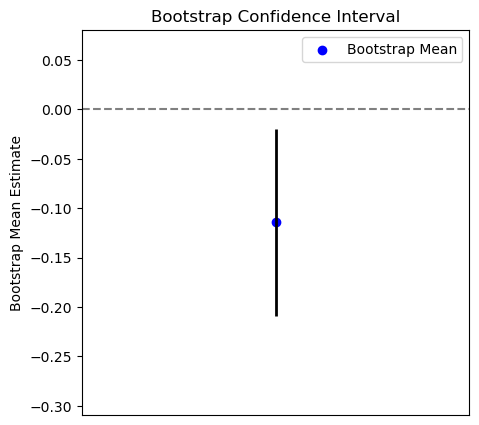

In [39]:
m=np.zeros(11)
q=np.zeros(11)
a=np.zeros(11)
b=np.zeros(11)

for j in range(0,11):
    
    #upwind_m[:,j]=upwind_m[:,j]/upwind_m[0,j]
    #print(upwind_m[:,j])
    
    #switch on if you want theta/theta_e---------------------------------------------------------------
    a=upwind_m[:,j]
    maschera = ~np.isnan(a)
    b=expval[:,j]
    #print(upwind_m[:,j])
    popt, pcov = curve_fit(func,b[maschera],a[maschera])#,sigma=city_m_std)
    #---------------------------------------------------------------------------------------------------

    #switch on if is not theta/theta_e 
    #popt, pcov = curve_fit(func,expval[:,j],upwind_m[:,j])#,sigma=city_m_std)
    
    #costruisco vettori con risultati fit
    m[j]=popt[0]
    q[j]=popt[1]

    # popt, pcov = curve_fit(func_quad,expval[:,j],upwind_m[:,j])#,sigma=city_m_std)
    # a[j]=popt[0]
    # b[j]=popt[1]

# am=np.mean(a)
# bm=np.mean(b)

print("PARAMETRI",np.mean(m),np.mean(q))
#print("PARAMETRI",am,bm)

# Compute ensemble differences
ens_diff = m-0
#ens_diffq = q

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)
        
df = pd.DataFrame({"errore": ens_diff})

# Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# Extract mean and confidence intervals
mean_m1 = np.mean(df["errore"])
low_m1, high_m1 = res.confidence_interval

# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_m1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_m1, high_m1, colors="red" if (low_m1 <= 0 <= high_m1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_m1 - 0.1, high_m1 + 0.1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_m1 <= 0 <= high_m1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_m1 <= 0 <= high_m1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

[[18.82051253 38.82887554 28.1160531  31.64330816 29.1730895  50.0654211
  34.64014482 38.38917589 24.53877306 27.79230165 38.46236944]
 [18.42844081 39.92206717 27.86884117 45.6170187  35.51715136 44.07888079
  34.63583183 36.95571566 22.84763145 27.47733641 37.52705097]
 [16.57358241 36.88298798 27.66593313 45.83090878 37.09230757 45.36800671
  32.97783566 34.83394289 20.70473003 27.90383244 36.02494907]
 [10.8978653  34.24252653 25.26852131 43.31282806 33.97275114 42.17300892
  30.39870787 31.68442011 15.63272119 26.18337488 33.79078722]
 [12.82818604 33.38961649 26.62071419 44.83086681 34.89550257 45.21942139
  32.45080996 32.46138239 16.24892974 26.93648195 34.09545135]
 [10.74216795 35.45478487 25.52084446 43.4584446  33.41739225 38.40086079
  30.46654081 31.47649097 16.31612802 26.12199879 33.81602764]
 [        nan 39.60358047 26.4352603  43.27241516 34.29734659 44.45874119
  33.59691381 34.76677227         nan 26.84892845 35.33461094]]
[18.82051253 18.42844081 16.57358241 10.8

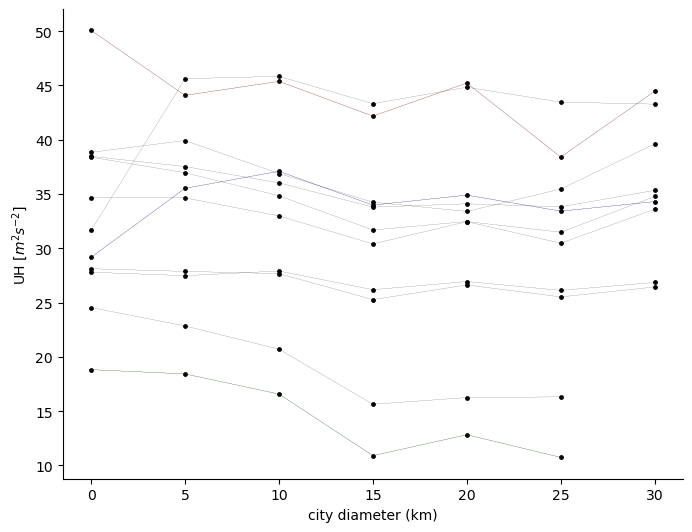

In [40]:
expval2=expval.flatten()
upwind_m2=upwind_m.flatten()

print(upwind_m)
fig=plt.figure(figsize=(8,6.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')

ax.scatter(expval2,upwind_m2,color='k',s=6)
ax.plot(expval[:,5],upwind_m[:,5],color='r',linewidth=0.1)
ax.plot(expval[:,4],upwind_m[:,4],color='b',linewidth=0.1)
ax.plot(expval[:,0],upwind_m[:,0],color='g',linewidth=0.1)
for i in range(0,11):
    ax.plot(expval[:,i],upwind_m[:,i],color='k',linewidth=0.1)
    print(upwind_m[:,i])
    #plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")
    #ax.scatter(expval[:,i],city_m[:,i],s=6)
# ax.errorbar(expval, city_m, yerr=city_m_std, fmt='o', color='k',capsize=5)
# ax.plot(exp,upwind_m,'b-',linewidth=3, label='upwind')
# ax.errorbar(exp, upwind_m, yerr=city_m_std, fmt='o', color='b',capsize=5)
# ax.plot(exp,downwind_m,'r-',linewidth=3, label='downwind')
# ax.errorbar(exp, downwind_m, yerr=downwind_m_std, fmt='o', color='r',capsize=5)
ivt_p=expval2

#plt.plot(ivt_p,mean_m1*ivt_p+1, "r-")

#plt.plot(ivt_p,am*ivt_p**2+bm*ivt_p+1, "m-")

# for i in range(0,11):
#     plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")
#ax.fill_between(ivt_p,low_m1*ivt_p+1,high_m1*ivt_p+1,color='red',alpha=0.1)

#ax.fill_between(ivt_p,low_a1*ivt_p**2+low_b1*ivt_p+1,high_a1*ivt_p**2+high_b1*ivt_p+1,color='m',alpha=0.1)

#plt.plot(ivt_p,m_low*ivt_p+q_low, "m-")
#.plot(ivt_p,m_high*ivt_p+q_high, "m-")
#plt.plot(ivt_p,a*ivt_p**2+b*ivt_p+c, "r-",linewidth=1.5)
#ax.text(0, 50, f"w_max=({mean_m1:.2f} *city diameter + {q_mean:.1f})m/s",color='r')
#ax.text(0, 17.5, f"r={r:.2f}")

# ax.plot(exp,away_m,'g-',linewidth=3, label='away')
# ax.errorbar(exp, away_m, yerr=away_m_std, fmt='o', color='g',capsize=5)

#SCOMMENTA PER VARIABILI NO THETA 
#ax.set_ylim(0.975,1.025)
#ax.set_ylim(0,1.5)
ax.set_ylabel('UH [$m^2s^{-2}$]')
ax.set_xlabel('city diameter (km)')
#ax.legend()
ax.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax.spines['right'].set_visible(False)  # Rimuove il bordo destro
#ax.grid(alpha=0.25)
#plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/phase_plot/regression_"+var+"_upwind.png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)
#print(exp,city_m)

[[14.31133127 62.49420357 37.97274399 52.59970665 49.1231308  77.79056835
  30.17724514 49.80863667 37.67120838 35.32594681 46.32626534]
 [14.33369946 55.60644436 31.57642174         nan 48.4677496  56.45319843
  43.03721428 51.35497952 28.93370104 28.61265755         nan]
 [13.61813581 61.63392735 36.89107084 45.25017118 54.23791409 25.28894091
  41.45269108 49.31135273 27.93480563 24.53150034 47.25048542]
 [        nan 48.23230171 30.04580593 49.56722641 45.34152699 56.50250244
  36.03376007 39.86026192 29.59095383         nan 44.61128902]
 [        nan 55.22114468 22.84402823 48.23014355 44.03895617 55.46319294
  38.7415123  44.05051708 30.7962327  29.57278681 40.30731201]
 [        nan 47.98340416 21.28177822 46.41309547 46.72782707 48.81171513
  36.58316851 44.82433796 32.30963135 23.08167434 38.99132442]
 [        nan 56.50462341         nan 49.42646599 39.14496231 57.17284489
  45.09317684 55.07807922         nan         nan 49.43976116]]
PARAMETRI LINEAR -0.18830397394335652 42

/glade/derecho/scratch/fdemartin/tmp/ipykernel_63383/1950734607.py:27: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(func_quad,b[maschera],a[maschera])#,sigma=city_m_std)


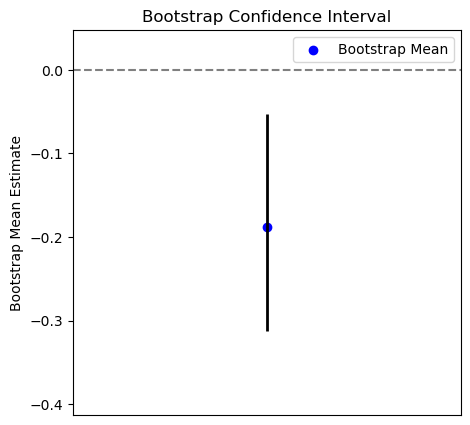

The bootstrap confidence interval does NOT cross zero.


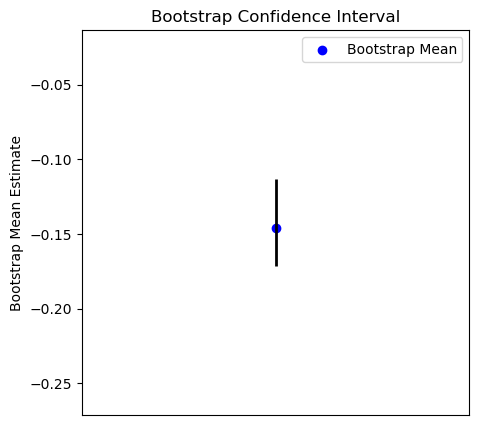

The bootstrap confidence interval does NOT cross zero.


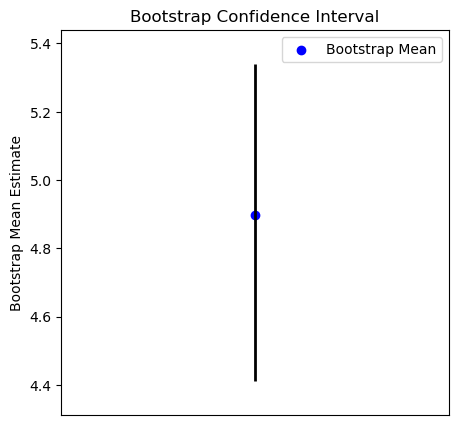

In [41]:
def func(x, m, q):
    return m*x+q

m=np.zeros(11)
q=np.zeros(11)
a1=np.zeros(11)
b1=np.zeros(11)
print(city_m)
for j in range(0,11):
    #print(downwind_m[:,j])
    city_m[:,j]=city_m[:,j]#/city_m[0,j]
    #print(city_m[:,j])
    # switch on if you want theta/theta_e---------------------------------------------------------------
    a=city_m[:,j]
    maschera = ~np.isnan(a)
    b=expval[:,j]
    #print(upwind_m[:,j])
    popt, pcov = curve_fit(func,b[maschera],a[maschera])#,sigma=city_m_std)
    #---------------------------------------------------------------------------------------------------
    
    #popt, pcov = curve_fit(func,expval[:,j],city_m[:,j])#,sigma=city_m_std)
    
    #costruisco vettori con risultati fit
    m[j]=popt[0]
    q[j]=popt[1]

    popt, pcov = curve_fit(func_quad,b[maschera],a[maschera])#,sigma=city_m_std)
    a1[j]=popt[0]
    b1[j]=popt[1]

am=np.mean(a1)
bm=np.mean(b1)

print("PARAMETRI LINEAR",np.mean(m),np.mean(q))
#print("PARAMETRI",am,bm)
# Compute ensemble differences
ens_diff = m-0
ens_diffq = q
ens_diffa = a1
ens_diffb = b1

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)
        

df = pd.DataFrame({"errore": ens_diff})

# Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# Extract mean and confidence intervals
mean_m1 = np.mean(df["errore"])
low_m1, high_m1 = res.confidence_interval

###################

df = pd.DataFrame({"errore": ens_diffq})

# Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# Extract mean and confidence intervals
mean_q1 = np.mean(df["errore"])
low_q1, high_q1 = res.confidence_interval

###################

df = pd.DataFrame({"errore": ens_diffa})

# Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# Extract mean and confidence intervals
mean_a1 = np.mean(df["errore"])
low_a1, high_a1 = res.confidence_interval

###################

df = pd.DataFrame({"errore": ens_diffb})

# Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# Extract mean and confidence intervals
mean_b1 = np.mean(df["errore"])
low_b1, high_b1 = res.confidence_interval

###################

# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_m1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_m1, high_m1, colors="red" if (low_m1 <= 0 <= high_m1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_m1 - 0.1, high_m1 + 0.1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_m1 <= 0 <= high_m1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_m1 <= 0 <= high_m1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

###################

# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_a1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_a1, high_a1, colors="red" if (low_a1 <= 0 <= high_a1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_a1 - 0.1, high_a1 + 0.1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_a1 <= 0 <= high_a1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_a1 <= 0 <= high_a1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

###################

# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_b1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_b1, high_b1, colors="red" if (low_b1 <= 0 <= high_b1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_b1 - 0.1, high_b1 + 0.1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_b1 <= 0 <= high_b1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_b1 <= 0 <= high_b1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

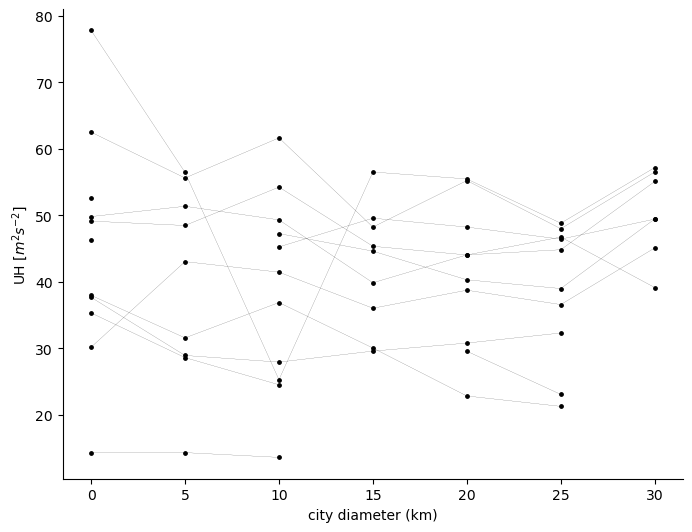

In [46]:
expval2=expval.flatten()
city_m2=city_m.flatten()

fig=plt.figure(figsize=(8,6.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.scatter(expval2,city_m2,color='k',s=6)
for i in range(0,11):
    ax.plot(expval[:,i],city_m[:,i],color='k',linewidth=0.1)
    #plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")
    #ax.scatter(expval[:,i],city_m[:,i],s=6)
#ax.errorbar(expval, city_m, yerr=city_m_std, fmt='o', color='k',capsize=5)
# ax.plot(exp,upwind_m,'b-',linewidth=3, label='upwind')
# ax.errorbar(exp, upwind_m, yerr=city_m_std, fmt='o', color='b',capsize=5)
# ax.plot(exp,downwind_m,'r-',linewidth=3, label='downwind')
# ax.errorbar(exp, downwind_m, yerr=downwind_m_std, fmt='o', color='r',capsize=5)
ivt_p=expval2
#plt.plot(ivt_p,mean_m1*ivt_p+np.mean(q), "r-")
#plt.plot(ivt_p,mean_m1*ivt_p+1, "r-")
#plt.plot(ivt_p,am*ivt_p**2+bm*ivt_p+1, "m-")

# for i in range(0,11):
#     plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")
#ax.fill_between(ivt_p,low_m1*ivt_p+np.mean(q),high_m1*ivt_p+np.mean(q),color='red',alpha=0.1)
#ax.fill_between(ivt_p,low_m1*ivt_p+1,high_m1*ivt_p+1,color='red',alpha=0.1)
#ax.fill_between(ivt_p,low_a1*ivt_p**2+low_b1*ivt_p+1,high_a1*ivt_p**2+high_b1*ivt_p+1,color='m',alpha=0.1)

#plt.plot(ivt_p,m_low*ivt_p+q_low, "m-")
#.plot(ivt_p,m_high*ivt_p+q_high, "m-")
#plt.plot(ivt_p,a*ivt_p**2+b*ivt_p+|c, "r-",linewidth=1.5)
#ax.text(0, 50, f"w_max=({mean_m1:.2f} *city diameter + {q_mean:.1f})m/s",color='r')
#ax.text(0, 17.5, f"r={r:.2f}")

# ax.plot(exp,away_m,'g-',linewidth=3, label='away')
# ax.errorbar(exp, away_m, yerr=away_m_std, fmt='o', color='g',capsize=5)

#ax.set_ylim(0.975,1.025)
#ax.set_ylim(0,1.5)
ax.set_ylabel('UH [$m^2s^{-2}$]')
ax.set_xlabel('city diameter (km)')
#ax.legend()
ax.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax.spines['right'].set_visible(False)  # Rimuove il bordo destro
#ax.grid(alpha=0.25)
#plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/phase_plot/regression_"+var+"_city.png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)
#print(exp,city_m)

[1.         0.97500332 0.88490517        nan        nan        nan
        nan]
[1.         1.0862556  0.79735998 0.84878382 0.84113461 0.74360758
 0.51130836]
[1.         0.82142027 0.95957167 0.77674717 0.94383307 1.10985381
        nan]
[1.                nan 1.02611656 0.93870388 1.04098799 0.97752664
 0.54936311]
[1.         0.99625054 1.17259654 1.02806843        nan 1.10260275
 1.03092697]
[1.         0.53359293        nan 0.34252522 0.62537456 0.70350819
 0.9484426 ]
[1.                nan 0.92491629 0.82651678 0.95215777 0.80212553
 0.80376479]
[1.         0.96540773 1.18924162 1.0525866  0.9405176  0.92867235
 1.20251572]
[1.         0.96856791 0.64120112 0.66295826 0.62481146 0.75341083
        nan]
[1.         1.26839093        nan        nan 1.10921926 0.58310059
        nan]
[1.                nan 0.82652135 0.81179358 0.77431032 0.88956274
 1.00620822]
PARAMETRI -0.005716581328498363 0.9784570088171942
The bootstrap confidence interval does NOT cross zero.


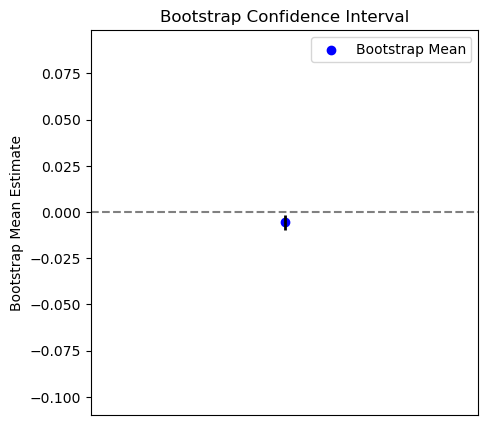

In [43]:
m=np.zeros(11)
q=np.zeros(11)
a=np.zeros(11)
b=np.zeros(11)

for j in range(0,11):
    #print(downwind_m[:,j])
    downwind_m[:,j]=downwind_m[:,j]/downwind_m[0,j]
    #popt, pcov = curve_fit(func,expval[:,j],downwind_m[:,j])#,sigma=city_m_std)
    a=downwind_m[:,j]
    maschera = ~np.isnan(a)
    b=expval[:,j]
    print(downwind_m[:,j])
    popt, pcov = curve_fit(func,b[maschera],a[maschera])#,sigma=city_m_std)
    #costruisco vettori con risultati fit
    m[j]=popt[0]
    q[j]=popt[1]

    # popt, pcov = curve_fit(func_quad,expval[:,j],downwind_m[:,j])#,sigma=city_m_std)
    # a[j]=popt[0]
    # b[j]=popt[1]

# am=np.mean(a)
# bm=np.mean(b)
    
print("PARAMETRI",np.mean(m),np.mean(q))
#print("PARAMETRI",am,bm)

# Compute ensemble differences
ens_diff = m-0
ens_diffq = q

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)
        
df = pd.DataFrame({"errore": ens_diff})

# Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# Extract mean and confidence intervals
mean_m1 = np.mean(df["errore"])
low_m1, high_m1 = res.confidence_interval

###################

# df = pd.DataFrame({"errore": ens_diffq})

# # Perform bootstrap with 10,000 resamples
# res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# # Extract mean and confidence intervals
# mean_q1 = np.mean(df["errore"])
# low_q1, high_q1 = res.confidence_interval

###################

# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_m1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_m1, high_m1, colors="red" if (low_m1 <= 0 <= high_m1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_m1 - 0.1, high_m1 + 0.1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_m1 <= 0 <= high_m1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_m1 <= 0 <= high_m1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

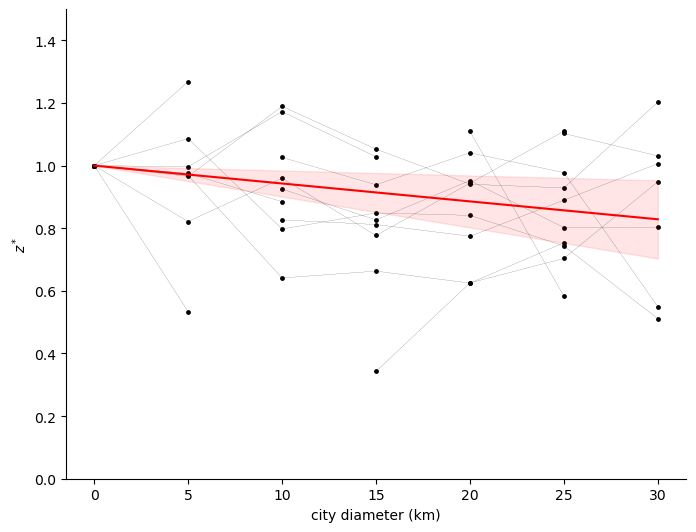

In [44]:
expval2=expval.flatten()
city_m2=downwind_m.flatten()

fig=plt.figure(figsize=(8,6.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.scatter(expval2,city_m2,color='k',s=6)
for i in range(0,11):
    ax.plot(expval[:,i],downwind_m[:,i],color='k',linewidth=0.1)
    #plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")
    #ax.scatter(expval[:,i],city_m[:,i],s=6)
#ax.errorbar(expval, city_m, yerr=city_m_std, fmt='o', color='k',capsize=5)
# ax.plot(exp,upwind_m,'b-',linewidth=3, label='upwind')
# ax.errorbar(exp, upwind_m, yerr=city_m_std, fmt='o', color='b',capsize=5)
# ax.plot(exp,downwind_m,'r-',linewidth=3, label='downwind')
# ax.errorbar(exp, downwind_m, yerr=downwind_m_std, fmt='o', color='r',capsize=5)

ivt_p=expval2
#plt.plot(ivt_p,mean_m1*ivt_p+np.mean(q), "r-")
plt.plot(ivt_p,mean_m1*ivt_p+1, "r-")
#plt.plot(ivt_p,am*ivt_p**2+bm*ivt_p+1, "m-")

# for i in range(0,11):
#     plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")

#ax.fill_between(ivt_p,low_m1*ivt_p+np.mean(q),high_m1*ivt_p+np.mean(q),color='red',alpha=0.1)
ax.fill_between(ivt_p,low_m1*ivt_p+1,high_m1*ivt_p+1,color='red',alpha=0.1)

#ax.fill_between(ivt_p,low_a1*ivt_p**2+low_b1*ivt_p+1,high_a1*ivt_p**2+high_b1*ivt_p+1,color='m',alpha=0.1)
#plt.plot(ivt_p,m_low*ivt_p+q_low, "m-")
#.plot(ivt_p,m_high*ivt_p+q_high, "m-")
#plt.plot(ivt_p,a*ivt_p**2+b*ivt_p+c, "r-",linewidth=1.5)
#ax.text(0, 50, f"w_max=({mean_m1:.2f} *city diameter + {q_mean:.1f})m/s",color='r')
#ax.text(0, 17.5, f"r={r:.2f}")

# ax.plot(exp,away_m,'g-',linewidth=3, label='away')
# ax.errorbar(exp, away_m, yerr=away_m_std, fmt='o', color='g',capsize=5)

#ax.set_ylim(0.975,1.025)
ax.set_ylim(0,1.5)
ax.set_ylabel('$z^*$')
ax.set_xlabel('city diameter (km)')
#ax.legend()
ax.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax.spines['right'].set_visible(False)  # Rimuove il bordo destro
#ax.grid(alpha=0.25)
#plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/phase_plot/regression_"+var+"_downwind.png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)
#print(exp,city_m)

In [30]:
upwind_theta=np.zeros(7)

for i in range(0,7):
    #upwind=[]
    for j in range(0,11):
        if upwind[i,j]!=0:
            upwind_m.append(UH[i,j])
        upwind_theta[i]=np.mean(upwind) 

expval=[0.,5.,10.,15.,20.,25.,30.]
expval=np.array(expval)

    #print(downwind_m[:,j])
#upwind_theta=upwind_theta/upwind_theta[0]
popt, pcov = curve_fit(func,expval,upwind_theta)#,sigma=city_m_std)
    
m=popt[0]

print(m)

upwind_theta=np.zeros(7)

for i in range(0,7):
    #upwind=[]
    for j in range(0,11):
        if upwind[i,j]!=0:
            upwind.append(city_m[i,j])
        upwind_theta[i]=np.mean(upwind) 

expval=[0.,5.,10.,15.,20.,25.,30.]
expval=np.array(expval)

    #print(downwind_m[:,j])
#upwind_theta=upwind_theta/upwind_theta[0]
popt, pcov = curve_fit(func,expval,upwind_theta)#,sigma=city_m_std)
    
m=popt[0]

print(m)

upwind_theta=np.zeros(7)

for i in range(0,7):
    upwind=[]
    for j in range(0,11):
        if upwind_m[i,j]!=0:
            upwind.append(downwind_m[i,j])
        upwind_theta[i]=np.mean(upwind) 

expval=[0.,5.,10.,15.,20.,25.,30.]
expval=np.array(expval)

    #print(downwind_m[:,j])
#upwind_theta=upwind_theta/upwind_theta[0]
popt, pcov = curve_fit(func,expval,upwind_theta)#,sigma=city_m_std)
    
m=popt[0]

print(m)

ens_diff = m-0

# Bootstrap function: Computes mean for resampling
def err_fun(data, axis):
  return np.mean(data, axis=axis)


df = pd.DataFrame({"errore": ens_diff})

# Perform bootstrap with 10,000 resamples
res = bootstrap((df["errore"].values,), err_fun, n_resamples=10000, method='basic')#,rng=1998)
    
# Extract mean and confidence intervals
mean_m1 = np.mean(df["errore"])
low_m1, high_m1 = res.confidence_interval

###################

# Plot the bootstrap confidence interval
plt.figure(figsize=(5, 5))
plt.scatter(1, mean_m1, color="blue", label="Bootstrap Mean")
plt.vlines(1, low_m1, high_m1, colors="red" if (low_m1 <= 0 <= high_m1) else "black", linewidth=2)
plt.axhline(y=0, color="gray", linestyle="dashed")

# Formatting
plt.xlim(0.5, 1.5)
plt.ylim(low_m1 - 0.1, high_m1 + 0.1)
plt.xticks([])
plt.ylabel("Bootstrap Mean Estimate")
plt.legend(["CI Crosses Zero" if (low_m1 <= 0 <= high_m1) else "Bootstrap Mean"], loc="upper right")
plt.title("Bootstrap Confidence Interval")

# Display result message
if low_m1 <= 0 <= high_m1:
  print("The bootstrap confidence interval crosses zero.")
else:
  print("The bootstrap confidence interval does NOT cross zero.")

plt.show()

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

In [ ]:
expval2=expval.flatten()
city_m2=downwind_m.flatten()

fig=plt.figure(figsize=(8,6.1))
ax = fig.add_subplot(1,1,1)
#ax.plot(time_no,UH[0,:],'r-',linewidth=1, label='control no urban')
#ax.plot(time_no,UH2[0,:],'m-',linewidth=1, label='control 20km')
#ax.plot(time_no,UH3[0,:],'k-',linewidth=1, label='control 10km')
ax.scatter(expval2,city_m2,color='k',s=6)
for i in range(0,11):
    ax.plot(expval[:,i],downwind_m[:,i],color='k',linewidth=0.1)
    #plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")
    #ax.scatter(expval[:,i],city_m[:,i],s=6)
#ax.errorbar(expval, city_m, yerr=city_m_std, fmt='o', color='k',capsize=5)
# ax.plot(exp,upwind_m,'b-',linewidth=3, label='upwind')
# ax.errorbar(exp, upwind_m, yerr=city_m_std, fmt='o', color='b',capsize=5)
# ax.plot(exp,downwind_m,'r-',linewidth=3, label='downwind')
# ax.errorbar(exp, downwind_m, yerr=downwind_m_std, fmt='o', color='r',capsize=5)

ivt_p=expval2
plt.plot(ivt_p,mean_m1*ivt_p+1, "r-")
#plt.plot(ivt_p,am*ivt_p**2+bm*ivt_p+1, "m-")

# for i in range(0,11):
#     plt.plot(ivt_p,m[i]*ivt_p+q[i], "b-")
ax.fill_between(ivt_p,low_m1*ivt_p+1,high_m1*ivt_p+1,color='red',alpha=0.1)
#ax.fill_between(ivt_p,low_a1*ivt_p**2+low_b1*ivt_p+1,high_a1*ivt_p**2+high_b1*ivt_p+1,color='m',alpha=0.1)
#plt.plot(ivt_p,m_low*ivt_p+q_low, "m-")
#.plot(ivt_p,m_high*ivt_p+q_high, "m-")
#plt.plot(ivt_p,a*ivt_p**2+b*ivt_p+c, "r-",linewidth=1.5)
#ax.text(0, 50, f"w_max=({mean_m1:.2f} *city diameter + {q_mean:.1f})m/s",color='r')
#ax.text(0, 17.5, f"r={r:.2f}")

# ax.plot(exp,away_m,'g-',linewidth=3, label='away')
# ax.errorbar(exp, away_m, yerr=away_m_std, fmt='o', color='g',capsize=5)

ax.set_ylim(0,1.5)
#ax.set_xlim(6,11)
ax.set_ylabel('$z^*$')
ax.set_xlabel('city diameter (km)')
#ax.legend()
ax.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax.spines['right'].set_visible(False)  # Rimuove il bordo destro
#ax.grid(alpha=0.25)
#plt.title('Max W')
plt.savefig("/glade/u/home/fdemartin/dati/phase_plot/regression_"+var+"_downwind.png", dpi = 300, bbox_inches = 'tight', pad_inches = 0)
#print(exp,city_m)